<div class="alert alert-block alert-info">

¡Hola Cristina! ¿Cómo va todo? 😊

Mi nombre es Revisor TripleTen. Es un gusto conocerte y seré tu revisor en este proyecto.

A continuación te comparto la modalidad de revisión que usaremos:

Cuando encuentre un error por primera vez, lo señalaré y te dejaré que lo detectes y corrijas por tu cuenta. Además, haré observaciones para mejorar tu código y comentarios sobre tus conclusiones.

Por favor **no muevas, modifiques ni elimines** mis comentarios.

Encontrarás mis comentarios en cuadros de colores:

</div>

<div class="alert alert-block alert-success">
<b>Comentario del revisor.</b> ✅ Éxito. Todo se ha hecho correctamente.
</div>

<div class="alert alert-block alert-warning">
<b>Comentario del revisor.</b> ⚠️ Observación. Algunas recomendaciones o mejoras menores.
</div>

<div class="alert alert-block alert-danger">
<b>Comentario del revisor.</b> ❌ Necesita corrección. El trabajo no puede ser aceptado con comentarios rojos.
</div>

<div class="alert alert-block alert-success">

<b>Review General — Iteración 1 ✅ PROYECTO APROBADO</b> <a class="tocSkip"></a>

¡Hola! Antes de entrar al detalle quiero compartirte mis apreciaciones generales.

Este proyecto está en un **nivel muy alto**. El análisis de valores ausentes cruzando cada columna con año de lanzamiento y nombre de plataforma (Cells 11-16) — buscando el patrón detrás de los nulos con hipótesis sobre Metacritic y la ESRB — es el más profundo y bien razonado de toda la serie. El razonamiento de negocio en cada sección, el análisis de tendencia de variación 2013→2016 (Cell 41), la justificación del período 2013+ (Cell 35), el análisis multiplataforma con `pivot_table` de `total_sales` y `critic_score`, y la conclusión de 8 puntos son todos elementos de calidad analítica real. ¡Muy buen trabajo!

**No hay ningún comentario rojo.**

**Tres observaciones menores:**

1. ⚠️ **Cell 8 — `user_score` sin conversión a tipo numérico.** Se reemplaza `"tbd"` y `pd.NA` por `np.nan`, pero falta el paso de conversión a `float`. Sin ese paso, la columna sigue siendo `object` y puede afectar el cálculo de correlaciones.

2. ⚠️ **Cell 45 — Boxplot sin `ylim` ni `showfliers=False`** — los outliers extremos comprimen las cajas y hacen difícil la comparación entre plataformas. En Cell 47 reconoces que los outliers distorsionan la imagen — sería consistente mostrar también una versión del boxplot sin ellos.

3. ⚠️ **H₀/H₁ como comentarios `#`** en el código en lugar de celdas markdown formales antes del código de cada hipótesis.

Con esos pequeños ajustes el proyecto queda impecable. ¡Felicitaciones! 🏆

</div>

- **Paso 1. Abrir el archivo y estudiar la información general**
  
  

In [1]:
# Importar las librerías

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats as st

In [2]:
# Cargar el archivo de datos en un DataFrame

df_games = pd.read_csv('/datasets/games.csv')

In [3]:
# Imprimir información del DF

print(df_games.head())
print(df_games.info())

                       Name Platform  Year_of_Release         Genre  NA_sales  \
0                Wii Sports      Wii           2006.0        Sports     41.36   
1         Super Mario Bros.      NES           1985.0      Platform     29.08   
2            Mario Kart Wii      Wii           2008.0        Racing     15.68   
3         Wii Sports Resort      Wii           2009.0        Sports     15.61   
4  Pokemon Red/Pokemon Blue       GB           1996.0  Role-Playing     11.27   

   EU_sales  JP_sales  Other_sales  Critic_Score User_Score Rating  
0     28.96      3.77         8.45          76.0          8      E  
1      3.58      6.81         0.77           NaN        NaN    NaN  
2     12.76      3.79         3.29          82.0        8.3      E  
3     10.93      3.28         2.95          80.0          8      E  
4      8.89     10.22         1.00           NaN        NaN    NaN  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 

- **Paso 2. Preparar los datos**

*2.1 Reemplazar los nombres de las columnas (cambiarlos a minúsculas)*

In [4]:
df_games.columns = df_games.columns.str.lower()
print(df_games.head())
print(df_games.info())

                       name platform  year_of_release         genre  na_sales  \
0                Wii Sports      Wii           2006.0        Sports     41.36   
1         Super Mario Bros.      NES           1985.0      Platform     29.08   
2            Mario Kart Wii      Wii           2008.0        Racing     15.68   
3         Wii Sports Resort      Wii           2009.0        Sports     15.61   
4  Pokemon Red/Pokemon Blue       GB           1996.0  Role-Playing     11.27   

   eu_sales  jp_sales  other_sales  critic_score user_score rating  
0     28.96      3.77         8.45          76.0          8      E  
1      3.58      6.81         0.77           NaN        NaN    NaN  
2     12.76      3.79         3.29          82.0        8.3      E  
3     10.93      3.28         2.95          80.0          8      E  
4      8.89     10.22         1.00           NaN        NaN    NaN  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 

*2.3 Convertir los datos en los tipos necesarios*

In [5]:
# Cambiar tipo de dato en columna user_score. Al tratarse de un rating, el dato debería se considerado como un número y no como un object. 
# Convertir el valor TBD a NaN para evitar error en la conversión del tipo de dato y convertir también el valor NAType

df_games['user_score'] = df_games['user_score'].replace(['tbd', pd.NA], np.nan)
print(df_games.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16715 entries, 0 to 16714
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   name             16713 non-null  object 
 1   platform         16715 non-null  object 
 2   year_of_release  16446 non-null  float64
 3   genre            16713 non-null  object 
 4   na_sales         16715 non-null  float64
 5   eu_sales         16715 non-null  float64
 6   jp_sales         16715 non-null  float64
 7   other_sales      16715 non-null  float64
 8   critic_score     8137 non-null   float64
 9   user_score       7590 non-null   float64
 10  rating           9949 non-null   object 
dtypes: float64(7), object(4)
memory usage: 1.4+ MB
None


<div class="alert alert-block alert-warning">
<b>Comentario del revisor — Iteración 1</b> <a class="tocSkip"></a>

⚠️ **Cell 8 — `user_score` sin conversión a tipo numérico después del `replace`**

```python
# Actual:
df_games["user_score"] = df_games["user_score"].replace(["tbd", pd.NA], np.nan)
```

El `replace` convierte `"tbd"` y `pd.NA` a `np.nan`, pero la columna sigue siendo de tipo `object` porque contiene valores string mezclados con NaN. Sin convertirla a `float`, cualquier operación numérica posterior (`.corr()`, `.mean()`, `.std()`, etc.) puede producir resultados incorrectos o errores silenciosos.

La corrección es agregar la conversión a `float` justo después:

```python
df_games["user_score"] = pd.to_numeric(
    df_games["user_score"].replace("tbd", np.nan),
    errors="coerce"
)
```

`pd.to_numeric(errors="coerce")` convierte cualquier valor no numérico a NaN automáticamente — es la forma más segura y directa. Una vez corregido, verifica que `df_games.info()` muestre `float64` para `user_score`.

</div>

*2.4 Tratamiento de valores ausentes*

In [6]:

# Rellenar los valores ausentes de name y de genre. Al ser solo dos encada uno, no nos distorsionarían demasiado los datos y al ser de tipo object, los podemos dejar como unknown

df_games['name'] = df_games['name'].fillna('unknown')
df_games['genre'] = df_games['genre'].fillna('unknown')

print(df_games.head())


                       name platform  year_of_release         genre  na_sales  \
0                Wii Sports      Wii           2006.0        Sports     41.36   
1         Super Mario Bros.      NES           1985.0      Platform     29.08   
2            Mario Kart Wii      Wii           2008.0        Racing     15.68   
3         Wii Sports Resort      Wii           2009.0        Sports     15.61   
4  Pokemon Red/Pokemon Blue       GB           1996.0  Role-Playing     11.27   

   eu_sales  jp_sales  other_sales  critic_score  user_score rating  
0     28.96      3.77         8.45          76.0         8.0      E  
1      3.58      6.81         0.77           NaN         NaN    NaN  
2     12.76      3.79         3.29          82.0         8.3      E  
3     10.93      3.28         2.95          80.0         8.0      E  
4      8.89     10.22         1.00           NaN         NaN    NaN  


In [7]:

# Como veo que en critic_score, user_score y rating tenemos demasiados valores ausentes, antes de decidir qué hacer con ellos, voy a ver si hay un patrón que nos indique a qué se debe


# Para critic_score, cruzar con años de lanzamiento para ver si hay relación obteniendo la proporción entre los vacíos y los años de lanzamiento
empty_per_year = df_games[df_games['critic_score'].isnull()]['year_of_release'].value_counts().sort_index()
total_per_year = df_games['year_of_release'].value_counts()
empty_proportion = (empty_per_year / total_per_year * 100).sort_index()
print(empty_proportion)



1980.0    100.000000
1981.0    100.000000
1982.0    100.000000
1983.0    100.000000
1984.0    100.000000
1985.0     92.857143
1986.0    100.000000
1987.0    100.000000
1988.0     93.333333
1989.0    100.000000
1990.0    100.000000
1991.0    100.000000
1992.0     97.674419
1993.0    100.000000
1994.0     99.173554
1995.0    100.000000
1996.0     96.958175
1997.0     94.117647
1998.0     92.612137
1999.0     88.461538
2000.0     59.142857
2001.0     32.365145
2002.0     24.366707
2003.0     24.516129
2004.0     26.377953
2005.0     30.244941
2006.0     38.369781
2007.0     42.188805
2008.0     49.894884
2009.0     54.347826
2010.0     60.159363
2011.0     55.985915
2012.0     50.842266
2013.0     49.816176
2014.0     55.077453
2015.0     62.871287
2016.0     53.784861
Name: year_of_release, dtype: float64


In [8]:


# para critic_score, cruzar con el nombre de las plataformas para ver si hay relación obteniendo la proporción entre los vacíos y estas

empty_per_platform = df_games[df_games['critic_score'].isnull()]['platform'].value_counts()
total_per_platform = df_games['platform'].value_counts()
empty_proportion = (empty_per_platform / total_per_platform * 100).sort_values(ascending=False)
print(empty_proportion)





2600    100.000000
PCFX    100.000000
WS      100.000000
TG16    100.000000
SNES    100.000000
GB      100.000000
SCD     100.000000
SAT     100.000000
GEN     100.000000
GG      100.000000
N64     100.000000
NES     100.000000
NG      100.000000
3DO     100.000000
PS       83.291562
DC       73.076923
PSV      72.093023
3DS      67.692308
DS       66.666667
PSP      61.786600
Wii      55.681818
GBA      46.715328
PS2      39.935215
WiiU     38.775510
PS3      38.392186
PS4      35.714286
XOne     31.578947
X360     27.416799
PC       26.591376
GC       19.424460
XB       12.014563
Name: platform, dtype: float64


In [9]:

# para user_score, cruzar con los años de lanzamiento para ver si hay relación obteniendo la proporción entre los vacíos y estos

empty_per_year_user = df_games[df_games['user_score'].isnull()]['year_of_release'].value_counts().sort_index()
total_per_year_user = df_games['year_of_release'].value_counts()
empty_proportion = (empty_per_year_user / total_per_year_user * 100).sort_values(ascending=False)
print(empty_proportion)



1980.0    100.000000
1987.0    100.000000
1995.0    100.000000
1993.0    100.000000
1991.0    100.000000
1990.0    100.000000
1981.0    100.000000
1989.0    100.000000
1986.0    100.000000
1984.0    100.000000
1983.0    100.000000
1982.0    100.000000
1994.0     99.173554
1992.0     97.674419
1996.0     96.958175
1997.0     93.771626
1988.0     93.333333
1985.0     92.857143
1998.0     91.820580
1999.0     90.828402
2000.0     69.428571
2010.0     62.788845
2009.0     56.942496
2011.0     55.897887
2008.0     53.679047
2015.0     50.990099
2012.0     48.085758
2016.0     47.808765
2007.0     47.451963
2001.0     46.680498
2006.0     45.129225
2013.0     44.117647
2002.0     44.028951
2014.0     43.373494
2005.0     37.912673
2004.0     35.826772
2003.0     33.419355
Name: year_of_release, dtype: float64


In [10]:
# para user_score, cruzar con el nombre de las plataformas para ver si hay relación obteniendo la proporción entre los vacíos y estas

empty_per_platform_user = df_games[df_games['user_score'].isnull()]['platform'].value_counts()
total_per_platform_user = df_games['platform'].value_counts()
empty_proportion = (empty_per_platform_user / total_per_platform_user * 100).sort_values(ascending=False)
print(empty_proportion)


2600    100.000000
PCFX    100.000000
WS      100.000000
TG16    100.000000
SNES    100.000000
GB      100.000000
SCD     100.000000
SAT     100.000000
GEN     100.000000
GG      100.000000
N64     100.000000
NES     100.000000
NG      100.000000
3DO     100.000000
PS       86.466165
DS       76.011158
DC       73.076923
GBA      68.978102
PSV      66.744186
3DS      66.538462
PSP      65.177833
Wii      57.575758
PS2      42.572883
PS4      34.438776
GC       34.172662
PS3      34.109692
WiiU     31.972789
XB       28.883495
XOne     26.315789
X360     23.454834
PC       20.944559
Name: platform, dtype: float64


In [11]:
# para rating, cruzar con los años de lanzamiento para ver si hay relación obteniendo la proporción entre los vacíos y estos

empty_per_year_rating = df_games[df_games['rating'].isnull()]['year_of_release'].value_counts().sort_index()
total_per_year_rating = df_games['year_of_release'].value_counts()
empty_proportion = (empty_per_year_rating / total_per_year_rating * 100).sort_values(ascending=False)
print(empty_proportion)

1980.0    100.000000
1987.0    100.000000
1995.0    100.000000
1993.0    100.000000
1991.0    100.000000
1990.0    100.000000
1981.0    100.000000
1989.0    100.000000
1986.0    100.000000
1984.0    100.000000
1983.0    100.000000
1982.0    100.000000
1994.0     99.173554
1996.0     97.338403
1992.0     95.348837
1997.0     93.425606
1988.0     93.333333
1985.0     92.857143
1998.0     91.556728
1999.0     87.573964
2000.0     57.714286
2015.0     48.019802
2012.0     45.635528
2016.0     44.223108
2013.0     41.911765
2014.0     40.619621
2011.0     38.116197
2010.0     36.334661
2006.0     32.604374
2007.0     31.411863
2008.0     31.254380
2001.0     29.668050
2009.0     29.102384
2005.0     24.813632
2004.0     21.522310
2002.0     20.989144
2003.0     20.903226
Name: year_of_release, dtype: float64


In [12]:
# para rating, cruzar con los nombres de las plataformas para ver si hay relación obteniendo la proporción entre los vacíos y estas

empty_per_year_platform_rating = df_games[df_games['rating'].isnull()]['platform'].value_counts().sort_index()
total_per_year_platform_rating = df_games['platform'].value_counts()
empty_proportion = (empty_per_year_platform_rating / total_per_year_platform_rating * 100).sort_values(ascending=False)
print(empty_proportion)

2600    100.000000
PCFX    100.000000
WS      100.000000
TG16    100.000000
SNES    100.000000
GB      100.000000
SCD     100.000000
SAT     100.000000
GEN     100.000000
GG      100.000000
N64     100.000000
NES     100.000000
NG      100.000000
3DO     100.000000
PS       82.623225
DC       73.076923
PSV      64.883721
3DS      56.153846
PSP      55.004136
DS       40.818224
GBA      36.496350
PS4      34.948980
PS2      31.466913
WiiU     28.571429
PS3      28.474831
XOne     24.696356
Wii      24.090909
PC       20.533881
X360     16.640254
GC       15.647482
XB       11.043689
Name: platform, dtype: float64


1. Convertir valores ausentes: me he encontrado con valores ausentes en las siguientes columnas. En cada una describo cómo he tratado esos valores:
    - year_of_release: por ahora, he decidido dejarlas como NaN, ya que rellenarlos con cero me distorsionaría análisis posteriores.
    - En user_score nos encontramos con un valor 'tbd' (significa to be determined y entiendo que se debe a que no se ha determinado todavía una calificación de la crítica para un juego) y con un valor NA. He decidio reemplazar estos dos valores a NaN, ya que dejarlos como están me podría generar conflicto en       pasos posteriores, por ejemplo, al intentar cambiar el tipo de dato a float en vez de object.
2. name y genre. Al ser solo dos valores ausentes en cada una y siendo tipo objeto, me ha parecido razonable rellenarlos con unknown, así no inventaría un valor y me será más útil para análisis posteriores que dejarlos vacíos.
3. En critic_score y en rating tenemos bastantes valores ausentes, no obstante, no los voy a rellenar todavía, ya que, según los cálculos que vaya a realizar más adelante, el     valor que decida ahora me podría sesgar los datos, por ejemplo, si los relleno con cero o si los relleno con la media.
4. Creo que los valores ausentes de name y genre se puede deber a un error al momento de la introducción de datos en el archivo. Al ser tan pocos, no veo indicios de un patrón que pueda tener una razón de peso sobre la que tengamos que indagar más.
5. Sobre los valores ausentes en critic_score, los he cruzado con los años de lanzamiento y los nombres de las plataformas y, con la suposición de que este score viene de la empresa Metacritic (el proyecto no especifica la fuente), que se fundó en el año 2000, podría inferir por los resultados que los valores nulos se concentran en mayor proporción antes de que existiera la empresa, así que no había quién les asignara un score. Lo mismo con las plataformas. Son ausentes porque las plataformas que existían antes de la existencia de Metacritic no había forma de que recibieran críticas de esta empresa. La disminución de los porcentajes de valores nulos, tanto de año de lanzamiento como de nombres de plataformas, va decreciendo a partir del 2000, lo que podría confirmar mi razonamiento relacionado con el año de fundación de Metacritic.
6. Sobre los valores ausentes en user_score, habiendo cruzado los datos también con año de lanzamiento y, dado que las mayores proporciones de nulos se concentran antes del año 2000, puedo inferir que los nulos se deben a que no estaba activo el portal de críticas y los usuarios no podían dejar sus valoraciones, ya que no tenían dónde hacerlo. Ahora bien, sobre los nombres de las plataformas, podemos ver que son consolas antiguas las que tienen todos los valores ausentes, así que, es probable que cuando se lanzaron los usuarios no tuvieran acceso a internet, además de que el portal de Metacritic no existía (al menos para las plataformas que tienen el 100% de valores nulos, ya que su lanzamiento fue antes del 2000).
7. Por último, en los valores ausentes de rating, podemos inferir que sucede algo parecido que con las columnas anteriores. En este caso, el rating viene de la ESBR, que se fundó en 1994, por lo tanto, las consolas que se lanzaron antes de ese año, simplemente no pueden tener un rating asociado. Vemos, no obstante, que también tenemos valores ausentes posteriores a 1994, aunque en menor medida, lo que nos podría indicar que la adopción del rankeo por edades de todas las plataformas se fue realizando de manera progresiva, no inmediatamente en cuanto se fundó la ESBR.

<div class="alert alert-block alert-success">
<b>Comentario del revisor — Iteración 1</b> <a class="tocSkip"></a>

✅ **Análisis de valores ausentes — el más profundo y bien razonado de toda la serie:**

- `name` y `genre`: rellenados con `"unknown"` — justificación correcta (pocos valores, tipo objeto). ✅
- `critic_score`: cruzado con año y plataforma + hipótesis sobre Metacritic (fundada en 2000). La proporción decreciente de nulos desde el año 2000 confirma el razonamiento. ✅
- `user_score`: cruzado con año y plataforma + hipótesis sobre acceso a internet y existencia de portales de crítica de usuarios. ✅
- `rating`: cruzado con año + hipótesis sobre la ESRB (fundada en 1994) y adopción progresiva. ✅

Cell 17 con los 7 puntos de síntesis es la justificación de valores ausentes más completa y bien razonada de toda la serie del sprint. ¡Excepcional!

</div>

*2.5 Calcular las ventas totales y colocarlas en una columna separada*

In [13]:
df_games['total_sales'] = df_games['na_sales'] + df_games['eu_sales'] + df_games['jp_sales'] + df_games['other_sales']
print(df_games.head())

                       name platform  year_of_release         genre  na_sales  \
0                Wii Sports      Wii           2006.0        Sports     41.36   
1         Super Mario Bros.      NES           1985.0      Platform     29.08   
2            Mario Kart Wii      Wii           2008.0        Racing     15.68   
3         Wii Sports Resort      Wii           2009.0        Sports     15.61   
4  Pokemon Red/Pokemon Blue       GB           1996.0  Role-Playing     11.27   

   eu_sales  jp_sales  other_sales  critic_score  user_score rating  \
0     28.96      3.77         8.45          76.0         8.0      E   
1      3.58      6.81         0.77           NaN         NaN    NaN   
2     12.76      3.79         3.29          82.0         8.3      E   
3     10.93      3.28         2.95          80.0         8.0      E   
4      8.89     10.22         1.00           NaN         NaN    NaN   

   total_sales  
0        82.54  
1        40.24  
2        35.52  
3        32.77  
4

<div class="alert alert-block alert-success">
<b>Comentario del revisor — Iteración 1</b> <a class="tocSkip"></a>

✅ **`total_sales` con las 4 regiones (Cell 19).** ✅

</div>

**Paso 3. Análisis de los datos**

*3.1 Mirar cuántos juegos fueron lanzados en diferentes años.*


In [14]:
# Encontrar cuántos juegos fueron lanzado en diferentes años

df_games['year_of_release'].value_counts().sort_index()


1980.0       9
1981.0      46
1982.0      36
1983.0      17
1984.0      14
1985.0      14
1986.0      21
1987.0      16
1988.0      15
1989.0      17
1990.0      16
1991.0      41
1992.0      43
1993.0      62
1994.0     121
1995.0     219
1996.0     263
1997.0     289
1998.0     379
1999.0     338
2000.0     350
2001.0     482
2002.0     829
2003.0     775
2004.0     762
2005.0     939
2006.0    1006
2007.0    1197
2008.0    1427
2009.0    1426
2010.0    1255
2011.0    1136
2012.0     653
2013.0     544
2014.0     581
2015.0     606
2016.0     502
Name: year_of_release, dtype: int64

*3.1.1 Describir sin son significativos los datos de cada periodo*

Vemos cómo en 1994 se produce un salto de 62 en 1993 a 121, no obstante, considerando los datos que hay en años posteriores, podríamos decir que el rango con los datos más significativos sería de 1998 a 2015. 

*3.2 Variación en las ventas de una plataforma a otra*

In [15]:
sales_per_platform = df_games.groupby('platform')['total_sales'].sum().sort_values(ascending=False)
print(sales_per_platform)

top_platforms = sales_per_platform.head(6).index.tolist()
print(top_platforms)

platform
PS2     1255.77
X360     971.42
PS3      939.65
Wii      907.51
DS       806.12
PS       730.86
GBA      317.85
PS4      314.14
PSP      294.05
PC       259.52
3DS      259.00
XB       257.74
GB       255.46
NES      251.05
N64      218.68
SNES     200.04
GC       198.93
XOne     159.32
2600      96.98
WiiU      82.19
PSV       54.07
SAT       33.59
GEN       30.77
DC        15.95
SCD        1.86
NG         1.44
WS         1.42
TG16       0.16
3DO        0.10
GG         0.04
PCFX       0.03
Name: total_sales, dtype: float64
['PS2', 'X360', 'PS3', 'Wii', 'DS', 'PS']


*3.2.1 Distribución de las ventas por año*

In [16]:
platforms_top = df_games[df_games['platform'].isin(top_platforms)]
platforms_distribution = platforms_top.groupby(['year_of_release', 'platform'])['total_sales'].sum().unstack()
print(platforms_distribution)


platform             DS      PS     PS2     PS3     Wii    X360
year_of_release                                                
1985.0             0.02     NaN     NaN     NaN     NaN     NaN
1994.0              NaN    6.03     NaN     NaN     NaN     NaN
1995.0              NaN   35.96     NaN     NaN     NaN     NaN
1996.0              NaN   94.70     NaN     NaN     NaN     NaN
1997.0              NaN  136.17     NaN     NaN     NaN     NaN
1998.0              NaN  169.49     NaN     NaN     NaN     NaN
1999.0              NaN  144.53     NaN     NaN     NaN     NaN
2000.0              NaN   96.37   39.17     NaN     NaN     NaN
2001.0              NaN   35.59  166.43     NaN     NaN     NaN
2002.0              NaN    6.67  205.38     NaN     NaN     NaN
2003.0              NaN    2.07  184.31     NaN     NaN     NaN
2004.0            17.27     NaN  211.81     NaN     NaN     NaN
2005.0           130.14     NaN  160.66     NaN     NaN    8.25
2006.0           119.81     NaN  103.42 

*3.2.2 Plataformas que solían ser populares pero que ahora no tienen ventas*

In [17]:
# Muestro las 25 plataformas que no han tenido ventas de 2015 en adelante

recent_sales = df_games[df_games['year_of_release'] >= 2015].groupby('platform')['total_sales'].sum()
defunct_platforms = sales_per_platform[~sales_per_platform.index.isin(recent_sales[recent_sales > 0].index)]
print(defunct_platforms.head(25))



platform
PS2     1255.77
DS       806.12
PS       730.86
GBA      317.85
XB       257.74
GB       255.46
NES      251.05
N64      218.68
SNES     200.04
GC       198.93
2600      96.98
SAT       33.59
GEN       30.77
DC        15.95
SCD        1.86
NG         1.44
WS         1.42
TG16       0.16
3DO        0.10
GG         0.04
PCFX       0.03
Name: total_sales, dtype: float64


*3.2.3 Encontrar cuánto tardan, generalmente, las nuevas plataformas en aparecer y las antiguas en desaparecer*

In [18]:
platforms_lifecycle = df_games.groupby('platform')['year_of_release'].agg(['min','max'])
platforms_lifecycle['lifespan'] = platforms_lifecycle['max'] - platforms_lifecycle['min']
print(platforms_lifecycle.sort_values('lifespan', ascending=False))



             min     max  lifespan
platform                          
PC        1985.0  2016.0      31.0
DS        1985.0  2013.0      28.0
GB        1988.0  2001.0      13.0
X360      2005.0  2016.0      11.0
PSP       2004.0  2015.0      11.0
PS2       2000.0  2011.0      11.0
NES       1983.0  1994.0      11.0
DC        1998.0  2008.0      10.0
Wii       2006.0  2016.0      10.0
PS3       2006.0  2016.0      10.0
2600      1980.0  1989.0       9.0
SNES      1990.0  1999.0       9.0
PS        1994.0  2003.0       9.0
XB        2000.0  2008.0       8.0
GBA       2000.0  2007.0       7.0
GC        2001.0  2007.0       6.0
N64       1996.0  2002.0       6.0
3DS       2011.0  2016.0       5.0
PSV       2011.0  2016.0       5.0
SAT       1994.0  1999.0       5.0
WiiU      2012.0  2016.0       4.0
GEN       1990.0  1994.0       4.0
NG        1993.0  1996.0       3.0
XOne      2013.0  2016.0       3.0
PS4       2013.0  2016.0       3.0
WS        1999.0  2001.0       2.0
3DO       1994.0  19

*3.3 Determinar para qué periodo tomar datos para comenzar a construir un modelo para 2017*

In [19]:
data_for_model = df_games[df_games['year_of_release'] >= 2013]
print(data_for_model)

                                name platform  year_of_release         genre  \
16                Grand Theft Auto V      PS3           2013.0        Action   
23                Grand Theft Auto V     X360           2013.0        Action   
31         Call of Duty: Black Ops 3      PS4           2015.0       Shooter   
33               Pokemon X/Pokemon Y      3DS           2013.0  Role-Playing   
42                Grand Theft Auto V      PS4           2014.0        Action   
...                              ...      ...              ...           ...   
16703               Strawberry Nauts      PSV           2016.0     Adventure   
16707               Aiyoku no Eustia      PSV           2014.0          Misc   
16710  Samurai Warriors: Sanada Maru      PS3           2016.0        Action   
16712        Haitaka no Psychedelica      PSV           2016.0     Adventure   
16714            Winning Post 8 2016      PSV           2016.0    Simulation   

       na_sales  eu_sales  jp_sales  ot

Para comenzar a construir el modelo para 2017, los datos que he utilizado son juegos lanzados de 2013 en adelante. Con ese margen de 4 años, me daría un volumen suficiente para poder obtener datos representativos, además ya que las plataformas activas en ese año comienzan su consolidación justo ahí. Si añado años anteriores, temo que mis datos se vean alterados por plataformas que en su día fueron muy populares, pero que ya habían terminado su ciclo de vida para 2016.

*3.4 Trabajar solo con los datos relevantes, ignorando los datos de años anteriores*

In [20]:
# Compruebo que mi nuevo dataset está filtrado correctamente y no me incluye toda la data de dataset orginal

data_for_model.shape



(2233, 12)

*3.5 Encontrar las plataformas líderes en ventas*

In [21]:
leading_sales_platforms = data_for_model.groupby('platform')['total_sales'].sum().sort_values(ascending=False)
print(leading_sales_platforms)

platform
PS4     314.14
PS3     181.43
XOne    159.32
3DS     143.25
X360    136.80
WiiU     64.63
PC       39.43
PSV      32.99
Wii      13.66
PSP       3.50
DS        1.54
Name: total_sales, dtype: float64


*3.5.1 Encontrar qué plataformas crecen y qué plataformas se reducen*

In [22]:
trend_by_year = data_for_model.groupby(['platform', 'year_of_release'])['total_sales'].sum().unstack()
print(trend_by_year)

trend_by_year['variation'] = trend_by_year[2016.0] - trend_by_year[2013.0]
print(trend_by_year['variation'].sort_values(ascending=False))

year_of_release  2013.0  2014.0  2015.0  2016.0
platform                                       
3DS               56.57   43.76   27.78   15.14
DS                 1.54     NaN     NaN     NaN
PC                12.38   13.28    8.52    5.25
PS3              113.25   47.76   16.82    3.60
PS4               25.99  100.00  118.90   69.25
PSP                3.14    0.24    0.12     NaN
PSV               10.59   11.90    6.25    4.25
Wii                8.59    3.75    1.14    0.18
WiiU              21.65   22.03   16.35    4.60
X360              88.58   34.74   11.96    1.52
XOne              18.96   54.07   60.14   26.15
platform
PS4      43.26
XOne      7.19
PSV      -6.34
PC       -7.13
Wii      -8.41
WiiU    -17.05
3DS     -41.43
X360    -87.06
PS3    -109.65
DS         NaN
PSP        NaN
Name: variation, dtype: float64


*3.5.2 Elegir varias plataformas potencialmente rentables*

Como plataformas rentables, en vista de la información observada en el paso anterior, elijo las que crecen:
- PS4, con el mayor crecimiento acumulado (43.26) y ventas absolutas más altas el último año
- XOne, la segunda con el mayor crecimiento acumulado (7.19)
Si bien ambas plataformas caen en 2016, esto parece ser una tendencia del mercado más que un problema específico de la plataforma.
El resto de las plataformas no las considero rentables ya que muestran un declive sostenido durante todo el periodo.


<div class="alert alert-block alert-success">
<b>Comentario del revisor — Iteración 1</b> <a class="tocSkip"></a>

✅ **Análisis de plataformas y período 2013-2016 (Cells 26-43)** — Muy sólido:

- Ciclo de vida con tabla `min / max / lifespan` (Cell 32). ✅
- `data_for_model` con corte en 2013 y justificación de 5 puntos en Cell 35. ✅
- Variación de tendencia 2013→2016 con diferencia absoluta (Cell 41) — un análisis creativo único en la serie. ✅
- Identificación de PS4 y XOne como potencialmente rentables con argumentación cuantitativa (Cell 43). ✅
- Nota de cautela sobre la caída de 2016 (datos posiblemente incompletos). ✅

</div>

*3.6 Crear un diagrama de cajas para las ventas globales de todos los juegos, desglosados por plataforma*

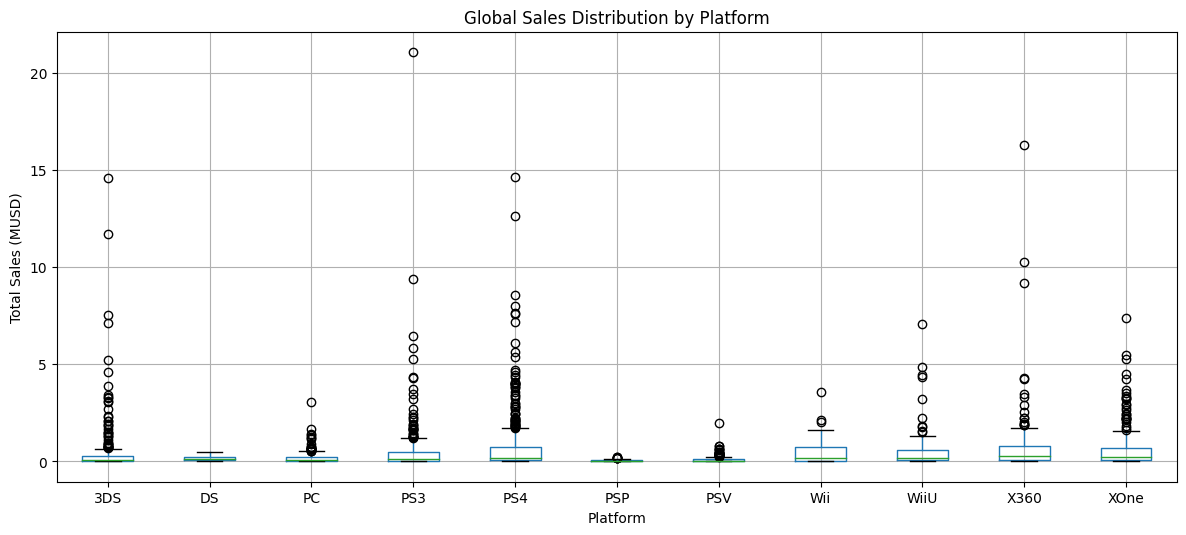

,mean,median,std,max
platform,,,,
PS4,0.801378,0.200,1.609456,14.63
X360,0.735484,0.265,1.663275,16.27
XOne,0.645020,0.220,1.036139,7.39
Wii,0.593913,0.180,0.915432,3.58
WiiU,0.562000,0.200,1.038778,7.09
PS3,0.525884,0.150,1.451939,21.05
3DS,0.472772,0.090,1.381347,14.60
PC,0.208624,0.080,0.352304,3.05
DS,0.192500,0.150,0.172026,0.51


In [23]:
data_for_model.boxplot(column='total_sales', by='platform', figsize=(14,6))
plt.title('Global Sales Distribution by Platform')
plt.suptitle('')
plt.xlabel('Platform')
plt.ylabel('Total Sales (MUSD)')
plt.show()

data_for_model.groupby('platform')['total_sales' ].agg(['mean', 'median', 'std', 'max']).sort_values('mean', ascending=False)

*3.6.1 Describir si son significativas las diferencias en las ventas y qué sucede con las ventas promedio en varias plataformas*

Respondiendo a la pregunta sobre si son significativas las diferencias en las ventas, si vemos solo las cajas, todas son muy parecidas entre sí; se sitúan en el cero y el uno.
Ahora bien, si revisamos los outliers, ahí sí que encontramos diferencias significativas. El más llamativo es el PS3, que alcanza de 21 millones y no hay ningún otro juego con ese volumen; el que más se le acerca es el X360, con 16 millones y PS4, con 14.6 millones. En contraste, tenemos a DS que no tiene outliers y a PSP con uno muy pequeño.

Viendo el panorma general, podemos responder a la pregunta Qué sucede con las ventas promedio de las plataformas, y sucede que observamos que en la gran mayoría de las plataformas, los juegos se venden poco, sin embargo, sí que hay unos pocos juegos que han sido top ventas, por lo tanto, si obtuvieramos un promedio de ventas de las plataformas y nos basaramos en este para tomar una decisión, no sería acertado. En los datos que nos arroja la estadística descriptiva podemos verlo claramente: la media está muy por encima de la mediana, por ejemplo, el PS4, con una media de 0.80 vs una mediana de 0.20.
En cuanto a la desviación estándar, también es coincidente la dispersión de en PS4 y X360 con sus outliers. En el opuesto, tenemos a DS con una disperión mínima, lo que nos confirma lo que vemos en el boxplot: una venta lineal, sin outliers extremos.

<div class="alert alert-block alert-warning">
<b>Comentario del revisor — Iteración 1</b> <a class="tocSkip"></a>

⚠️ **Cell 45 — Boxplot sin `ylim` ni `showfliers=False`**

El `df.boxplot()` nativo muestra todos los outliers extremos, lo que comprime las cajas en la parte inferior y hace difícil la comparación de medianas entre plataformas. En Cell 47 tú mismo reconoces este problema: *"si vemos solo las cajas, todas son muy parecidas entre sí; se sitúan en el cero y el uno"*.

Para mostrar la distribución central de forma legible, te recomendamos agregar una segunda versión con `sns.boxplot`:

```python
plt.figure(figsize=(14, 6))
sns.boxplot(
    data=data_for_model,
    x="platform", y="total_sales",
    showfliers=False
)
plt.ylim(0, 3)
plt.title("Distribución de ventas por plataforma (sin outliers)")
plt.xticks(rotation=45)
plt.show()
```

Con `showfliers=False` y `ylim(0, 3)` las diferencias en las medianas entre PS4, XOne y las demás plataformas son claramente visibles. El análisis de Cell 47 es correcto en su interpretación — solo falta el gráfico que lo acompañe visualmente. ✅

</div>

*3.7 Mirar cómo las reseñas de usuarios y profesionales afectan a las ventas de una plataforma popular.* 

*3.7.1 Para PS4 (plataforma popular de mi elección), crear gráfico de dispersión para encontrar la relación entre critic score y ventas totales*

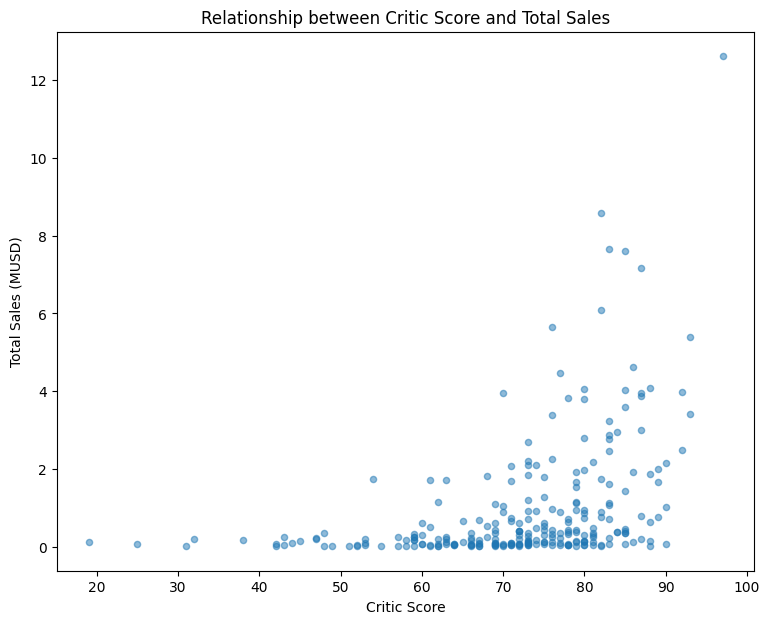

In [24]:
# Elijo PS4 por ser la líder de ventas y por su volumen de datos

ps4 = data_for_model[data_for_model['platform'] == 'PS4']


ps4.plot(kind='scatter', x='critic_score', y='total_sales', figsize=(9,7), alpha=0.5)
plt.title('Relationship between Critic Score and Total Sales')
plt.xlabel('Critic Score')
plt.ylabel('Total Sales (MUSD)')
plt.show()


*3.7.2 Para PS4 (plataforma popular de mi elección), crear gráfico de dispersión para encontrar la relación entre users score y ventas totales*

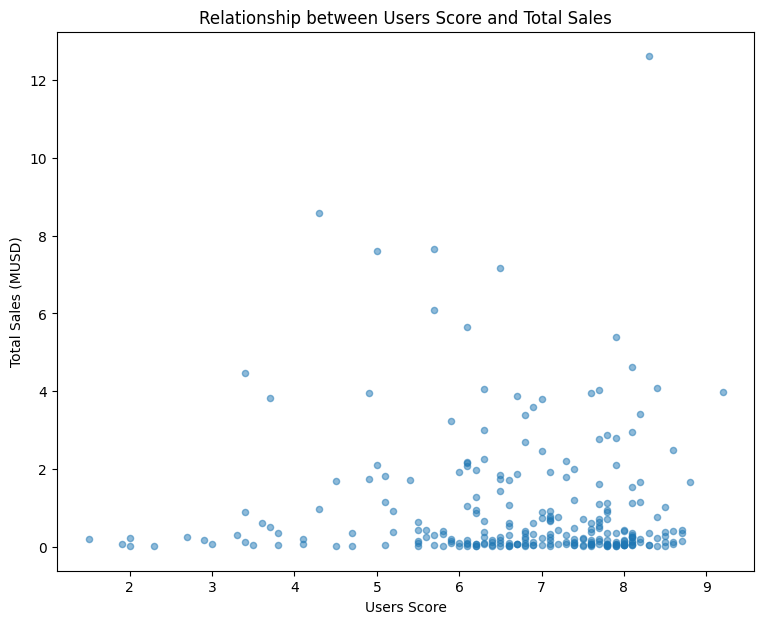

In [25]:
# Crear un gráfico de dispersión para calcular la correlación entre las reseñas de los usuarios y las ventas

ps4.plot(kind='scatter', x='user_score', y='total_sales', figsize=(9,7), alpha=0.5)
plt.title('Relationship between Users Score and Total Sales')
plt.xlabel('Users Score')
plt.ylabel('Total Sales (MUSD)')
plt.show()

*3.7.3 Calcular la correlación entre las reseñas y las ventas*

In [26]:
correlation_critic_score = ps4['critic_score'].corr(ps4['total_sales'])
correlation_users_score = ps4['user_score'].corr(ps4['total_sales'])

print(f'Correlation between critic score and total sales: {correlation_critic_score:.2f}')
print(f'Correlation between users score and total sales: {correlation_users_score:.2f}')

Correlation between critic score and total sales: 0.41
Correlation between users score and total sales: -0.03


*3.7.4 Conclusiones*

Analizando la relación entre reseñas y ventas, según los resultados observados en los gráficos de dispersión y en el cálculo de correlación, encontramos lo siguiente:
* Relación entre reseñas de profesionales y ventas: 0.41 nos indica una correlación positiva, aunque moderada. Es decir, los juegos con mayor puntuación de los críticos, sí tienden a vender más, aunque no podemos decir que es el único factor decisivo, ya que la correlación no es tan fuerte como para afirmarlo.
* Relación entre reseñas de usuarios y ventas: la correlación es de -0.03, lo que indica que las reseñas de estos no influyen en las ventas. El score de usuarios no repercute en la decisión de compra de la misma manera en que lo hacen las reseñas de los críticos.

<div class="alert alert-block alert-success">
<b>Comentario del revisor — Iteración 1</b> <a class="tocSkip"></a>

✅ **Correlación PS4 (Cells 50-56)** — Bien ejecutada:

- Elección justificada de PS4 (líder de ventas + mayor volumen de datos). ✅
- Scatterplots separados para críticos y usuarios. ✅
- Coeficientes calculados explícitamente (0.41 y -0.03). ✅
- Conclusión de Cell 56: "correlación no es causalidad" y "hay factores adicionales" — interpretación estadística correcta. ✅

</div>

*3.8 Comparar las ventas de los mismos juegos en otras plataformas*

In [27]:
# Comienzo con la identificación de los juegos que aparecen en más de una plataforma

games_by_platform = data_for_model.groupby('name')['platform'].nunique()
games_by_platform = games_by_platform[games_by_platform > 1]
print(games_by_platform.sort_values(ascending=False).head(25))

name
LEGO Marvel Super Heroes                    9
FIFA 14                                     9
Lego Batman 3: Beyond Gotham                8
LEGO Jurassic World                         8
The LEGO Movie Videogame                    8
Angry Birds Star Wars                       8
FIFA 15                                     8
LEGO The Hobbit                             8
Skylanders SWAP Force                       7
Skylanders: SuperChargers                   7
LEGO Marvel's Avengers                      7
Terraria                                    7
The Amazing Spider-Man 2 (2014)             7
Lego Star Wars: The Force Awakens           7
Skylanders: Trap Team                       7
Just Dance 2017                             6
Call of Duty: Ghosts                        6
Minecraft                                   6
Watch Dogs                                  6
Rugby World Cup 2015                        6
Disney Infinity 2.0: Marvel Super Heroes    6
Disney Infinity              

In [28]:
# Calcular y mostrar el critic score y las ventas por plataforma

sales_games_by_platform = games_by_platform.sort_values(ascending=False).head(10).index.tolist()
comparison = data_for_model[data_for_model['name'].isin(sales_games_by_platform)] 
comparison_chart = comparison.pivot_table(index='name', columns='platform', values=['total_sales', 'critic_score'])
comparison_chart = comparison_chart.swaplevel(axis=1).sort_index(axis=1)
print(comparison_chart)

platform                              3DS                      DS  \
                             critic_score total_sales total_sales   
name                                                                
Angry Birds Star Wars                 NaN        0.33         NaN   
FIFA 14                               NaN        0.23         NaN   
FIFA 15                               NaN        0.46         NaN   
LEGO Jurassic World                   NaN        0.62         NaN   
LEGO Marvel Super Heroes             61.0        0.89        0.38   
LEGO The Hobbit                       NaN        0.24         NaN   
Lego Batman 3: Beyond Gotham          NaN        0.45         NaN   
Skylanders SWAP Force                68.0        0.24         NaN   
Skylanders: SuperChargers             NaN        0.12         NaN   
The LEGO Movie Videogame              NaN        0.69         NaN   

platform                               PC                      PS3  \
                             cri

*3.8.1 Conclusión*

Si relacionamos los resultados de esta tabla con las observaciones del paso anterior, vemos que la reseña por sí sola no determina el volumen de ventas de un juego, sino que también influye la plataforma y la base de usuarios de cada plataforma. Tomamos como ejemplo los juegos FIFA 14 y FIFA 15 para PS4, donde FIFA 14 tuvo una crítica de 87 y una venta de 3 millones, mientras que FIFA 15, con un score de 82 tuvo una venta de 6 millones.

<div class="alert alert-block alert-success">
<b>Comentario del revisor — Iteración 1</b> <a class="tocSkip"></a>

✅ **Análisis multiplataforma (Cells 58-61)** — Bien construido. La tabla pivot con `total_sales` y `critic_score` para los top 10 juegos multiplataforma (Cell 59) y la conclusión de Cell 61 sobre la independencia entre reseña y ventas (ejemplo FIFA 14 vs FIFA 15) son hallazgos concretos y bien argumentados. ✅

</div>

*3.9 Encontrar la distribución general de los juegos por género*

In [29]:
# Comenzamos por contar cuántos juegos hay de cada genero

data_for_model['genre'].value_counts()


Action          766
Role-Playing    292
Adventure       245
Sports          214
Shooter         187
Misc            155
Racing           85
Fighting         80
Platform         74
Simulation       62
Strategy         56
Puzzle           17
Name: genre, dtype: int64

In [30]:
# Calculamos las ventas por género

sales_by_genre = data_for_model.groupby('genre')['total_sales'].sum().sort_values(ascending=False)
print(sales_by_genre)

genre
Action          321.87
Shooter         232.98
Sports          150.65
Role-Playing    145.89
Misc             62.82
Platform         42.63
Racing           39.89
Fighting         35.31
Adventure        23.64
Simulation       21.76
Strategy         10.08
Puzzle            3.17
Name: total_sales, dtype: float64


In [37]:
# En los dos pasos anteriores vemos que el volumen de juego por género parece estar relacionado con el volumen de ventas, buscaremos lo que nos dice la estadística descriptiva para ver si es real

data_for_model.groupby('genre')['total_sales'].agg(['count', 'mean', 'median', 'sum']).sort_values('count', ascending=False)



,count,mean,median,sum
genre,,,,
Action,766,0.420196,0.110,321.87
Role-Playing,292,0.499623,0.125,145.89
Adventure,245,0.096490,0.030,23.64
Sports,214,0.703972,0.240,150.65
Shooter,187,1.245882,0.450,232.98
Misc,155,0.405290,0.100,62.82
Racing,85,0.469294,0.120,39.89
Fighting,80,0.441375,0.125,35.31
Platform,74,0.576081,0.225,42.63


*3.9.1 ¿Qué se puede decir de los géneros más rentables? ¿Se puede genaralizar acerca de los géneros conn ventas altas y bajas?*

Acerca de los géneros más rentables, basándonos en la mediana, vemos a Shooter el que destaca sobre el resto y con diferencia. Si nos fijamos en la media, también Shooter destaca con la más alta, así que este género vende significativamente más que el resto de los juegos.

Observando los datos de la tabla, vemos que no se puede generalizar acerca de la relación entre el total de ventas y rentabilidad. El ejemplo más claro es el género Action que tiene las ventas más altas de todos, pero el valor de su media (0.42) y su mediana (0.11) nos indica que el volumen de venta se debe a que es el género con mayor número de juegos, no porque sea el más rentable.

También vemos que con el género Adventure pasa algo parecido. Es el tercer género con mayor volumen por número de juegos, sin embargo su mediana es de 0.03, lo que nos dice que aunque tenga muchos juegos, estos se venden poco.

<div class="alert alert-block alert-success">
<b>Comentario del revisor — Iteración 1</b> <a class="tocSkip"></a>

✅ **Géneros (Cells 63-67)** — Análisis correcto con la distinción clave:

- `count`, `mean`, `median`, `sum` por género (Cell 65). ✅
- Cell 67: la distinción entre Action (mayor volumen total pero mediana baja) y Shooter (la mediana y media más altas) es exactamente la conclusión correcta. ✅
- La observación de que "el volumen de juegos de un género no implica rentabilidad" (Adventure) es un insight analítico sofisticado. ✅

</div>

* **Paso 4. Crea un perfil de usuario para cada región** 

*4.1 Para cada región, determinar las cinco plataformas principales y describir las variaciones en sus cuotas de mercado de una región a otra*

In [38]:
top_platforms_na = data_for_model.groupby('platform')['na_sales'].sum().sort_values(ascending=False).head(5)
top_platforms_eu = data_for_model.groupby('platform')['eu_sales'].sum().sort_values(ascending=False).head(5) 
top_platforms_jp = data_for_model.groupby('platform')['jp_sales'].sum().sort_values(ascending=False).head(5)


print(top_platforms_na)
print(top_platforms_eu)
print(top_platforms_jp)



platform
PS4     108.74
XOne     93.12
X360     81.66
PS3      63.50
3DS      38.20
Name: na_sales, dtype: float64
platform
PS4     141.09
PS3      67.81
XOne     51.59
X360     42.52
3DS      30.96
Name: eu_sales, dtype: float64
platform
3DS     67.81
PS3     23.35
PSV     18.59
PS4     15.96
WiiU    10.88
Name: jp_sales, dtype: float64


*4.1.1 Descripción*

PS4 es la líder en ventas en EU y en NA, mientras que en en JP, está en el top 4 con apenas 15.96 millones, frente a 141 y 108 millones de EU y NA.
3DS también coincide en EU y NA como la plataforma con menor venta, mientras que en JP es la líder del ranking.
XOne aparece en segundo lugar en el top de NA y tercero en NA, mientras que en JP ni siquiera está en su top 5 de plataformas.
Con WiiU ocurre que en JP está en su ranking, mientras que en NA y EU no aparece en el top 5.
En NA y EN parece que siguen tendencia similar, mientras que JP presenta comportamiento diferente de las otras dos regiones.

*4.2 Para cada región, determinar los cinco géneros principales y describir la diferencia.*

In [39]:
top_genres_na = data_for_model.groupby('genre')['na_sales'].sum().sort_values(ascending=False).head(5)
top_genres_eu = data_for_model.groupby('genre')['eu_sales'].sum().sort_values(ascending=False).head(5) 
top_genres_jp = data_for_model.groupby('genre')['jp_sales'].sum().sort_values(ascending=False).head(5)


print(top_genres_na)
print(top_genres_eu)
print(top_genres_jp)



genre
Action          126.05
Shooter         109.74
Sports           65.27
Role-Playing     46.40
Misc             27.49
Name: na_sales, dtype: float64
genre
Action          118.13
Shooter          87.86
Sports           60.52
Role-Playing     36.97
Racing           20.19
Name: eu_sales, dtype: float64
genre
Role-Playing    51.04
Action          40.49
Misc             9.20
Fighting         7.65
Shooter          6.61
Name: jp_sales, dtype: float64


*4.2.1 Descripción*

En cuanto a los géneros por región, en NA y en EU, sus top 4 géneros son los mismos: Action, Shooter, Sports y Role-Playing, mientras que en JP, Role-Playing es el top 1 y Shooter el su top 5. Así como vimos en la venta por región, en la venta por género vemos que región JP presenta un comportamiento distinto, mientras que en NA y EU se ve una tendencia similar.

*4.3 Encontrar si las clasificaciones de ESRB afectan a las ventas en regiones individuales*

In [40]:
# Clasificación rating: E(todos), E10+(mayores de 10 años), T(adolescentes, mayores de 13 años), M(maduro, adultos, mayores de 17 años)

rating_na = data_for_model.groupby('rating')['na_sales'].sum().sort_values(ascending=False).head(5)
rating_eu = data_for_model.groupby('rating')['eu_sales'].sum().sort_values(ascending=False).head(5) 
rating_jp = data_for_model.groupby('rating')['jp_sales'].sum().sort_values(ascending=False).head(5)


print(rating_na)
print(rating_eu)
print(rating_jp)

# Mostrar la relación ventas/rating

data_for_model.groupby(['genre', 'rating'])['total_sales'].sum().unstack()

rating
M       165.21
E        79.05
E10+     54.24
T        49.79
Name: na_sales, dtype: float64
rating
M       145.32
E        83.36
E10+     42.69
T        41.95
Name: eu_sales, dtype: float64
rating
T       20.59
E       15.14
M       14.11
E10+     5.89
Name: jp_sales, dtype: float64


rating,E,E10+,M,T
genre,,,,
Action,14.74,45.25,168.60,29.87
Adventure,1.55,2.33,7.58,0.59
Fighting,NaN,1.18,4.23,13.29
Misc,7.21,14.91,1.55,4.87
Platform,20.48,15.18,NaN,0.58
Puzzle,1.34,0.99,NaN,NaN
Racing,24.63,7.92,0.10,2.74
Role-Playing,1.67,2.66,39.78,22.52
Shooter,NaN,9.06,149.49,31.39


*4.3.1 Descripción*

Observando los datos de rating, igual que vimos en las ventas por plataforma y por género, en NA y en EU vemos tendencias muy similares; en las dos regiones el orden del rating es igual (M, E, E10+ y T) y en ambas predomina el rating M. Comparando estos comportamientos con JP, encontramos que es totalmente distinto. En esta región, los juegos para adolescentes (T) son los que lideran y los géneros M caen al tercer lugar. 
Dados los resultados que observamos, es poco probable que las clasificaciones de ESRB tenga efecto directo en las ventas. Es más factible que infuya el factor género del juego. Por ejemplo, los géneros Action y Shooter, donde la clasificación con mayor venta es la M.

<div class="alert alert-block alert-success">
<b>Comentario del revisor — Iteración 1</b> <a class="tocSkip"></a>

✅ **Perfil regional (Cells 70-80)** — Completo y bien diferenciado:

- Top 5 plataformas por región (Cell 70). ✅
- Top 5 géneros por región (Cell 74). ✅
- ESRB por región con análisis de impacto (Cell 78). ✅
- Cell 72: diferencias NA/EU vs JP bien identificadas con cifras concretas. ✅
- Cell 80: observación de que la clasificación ESRB puede estar más correlacionada con el género del juego que con las ventas directamente — insight sofisticado. ✅

</div>

**Paso 5. Prueba de hipótesis**

*5.1 Las calificaciones promedio de los usuarios para las plataformas Xbox One y PC son las mismas.*

In [41]:
# Hipótesis nula: las calificaciones promedio de los usuarios para las plataformas Xbox One y PC son las mismas
# Hipótesis alternativa: las calificaciones promedio de los usuarios para las plataformas Xbox One y PC son diferentes

xone_scores = data_for_model[data_for_model['platform'] == 'XOne']['user_score'].dropna()
pc_scores = data_for_model[data_for_model['platform'] == 'PC']['user_score'].dropna()

alpha = 0.05

result = st.ttest_ind(xone_scores, pc_scores, equal_var=False)

print(f'Valor_p: {result.pvalue:.2f}')

if result.pvalue < alpha:
    print('Rechazamos H0: las calificaciones promedio son diferentes')
else:
    print('No podemos rechazar H0: no hay evidencia suficiente de diferencia')





Valor_p: 0.15
No podemos rechazar H0: no hay evidencia suficiente de diferencia


Partiendo de la base de que la H0 que nos indica el ejercicio es que las las calificaciones promedio de los usuarios para Xbox One y PC son las mismas, planteo la H1 de que las calificaciones promedio de los usuarios para estas plataformas son diferentes. Establezco el umbral de significancia en 0.05 por ser el estándar más común en estadística.
Al realizar la prueba t para probar la hipótesis, el resultado de pvalue arrojado es de 0.15, tres veces mayor que el valor de alpha, por lo tanto, no tenemos evidencia suficiente para probar que las calificaciones son diferentes.

*5.2 Las calificaciones promedio de los usuarios para los géneros de Acción y Deportes son diferentes*

In [42]:
# Hipótesis nula: las calificaciones promedio de los usuarios para los géneros de Acción y Deportes son iguales
# Hipótesis alternativa: las calificaciones promedio de los usuarios para los géneros de Acción y Deportes son diferentes

action_scores = data_for_model[data_for_model['genre'] == 'Action']['user_score'].dropna()
sports_scores = data_for_model[data_for_model['genre'] == 'Sports']['user_score'].dropna()

alpha = 0.05

result = st.ttest_ind(action_scores, sports_scores, equal_var=False)

print(f'Valor_p: {result.pvalue:.2f}')

if result.pvalue < alpha:
    print('Rechazamos H0: las calificaciones promedio son diferentes')
else:
    print('No podemos rechazar H0: no hay evidencia suficiente de que las calificaciones sean iguales')

Valor_p: 0.00
Rechazamos H0: las calificaciones promedio son diferentes


Partiendo del planteamiendo del ejercicio de que las calificaciones promedio de los usuarios para los géneros de Acción y Deportes son diferentes, tomo eso como H1 y planteo HO como que las calificaciones de estos generos son iguales, basada en lo que es convencional en las pruebas de hipótesis. Establezco el umbral de significancia en 0.05 por ser el estándar más común en estadística. Al realizar la prueba t para probar la hipótesis, el resultado de pvalue arrojado es de 0.00, muy por debajo del valor de significancia establecido, por lo tanto, rechazamos la hipótesis nula, pues existe evidencia suficiente para afirmar que las calificaciones promedio de los usuarios para los géneros Acción y deportes son diferentes.

<div class="alert alert-block alert-warning">
<b>Comentario del revisor — Iteración 1</b> <a class="tocSkip"></a>

⚠️ **Hipótesis (Cells 83 y 86) — H₀/H₁ como comentarios `#` en lugar de markdown**

La implementación técnica es correcta en todos los aspectos: `data_for_model` (2013-2016), `dropna()`, `equal_var=False` (Welch), `alpha = 0.05`, lógica `if/else` con texto interpretativo. ✅

La única mejora es mover H₀ y H₁ a una celda de **markdown** antes del código de cada hipótesis, para que se rendericen como texto formateado:

```markdown
**Hipótesis 1 — XOne vs PC:**
- H₀: Las calificaciones promedio de usuarios de XOne y PC son iguales.
- H₁: Las calificaciones promedio de usuarios de XOne y PC son diferentes.
- α = 0.05
```

Las conclusiones de Cells 84 y 87 son precisas y bien razonadas — la justificación de Cell 84 (*"el resultado de pvalue arrojado es de 0.15, tres veces mayor que el valor de alpha"*) es una interpretación estadística correcta y bien comunicada. ✅

</div>

**Paso 6. Escribe una conclusión general**

*Conclusión general:*



El análisis del dataset nme permitió encontrar varios patrones relevantes de cara a la construcción de un modelo para pronosticar las ventas de 2017.

**1. Preparación y limpieza de datos:** 
* Valores ausentes: encontré gran volumen de valores ausentes en los datos de critic_score, user_score y rating y he relacionado la falta de información con el año de lanzamiento de las compañias que emiten las valoraciones de critic_score y de rating y el escaso o nulo acceso a internet/plataformas de los usuarios para dejar reseñas. En columnas de nombre y género el número de valores nulos era pequeño, así que inferí que, posiblemente, se debió a que no se incluyeron en el archivo.
  
**2. Selección del periodo de análisis:**
* Con base en las observaciones del ciclo de vida de las plataformas, decidí trabajar con los datos desde el 2013 en adelante para contruir el modelo de predicción para 2017, así no incluiría datos de plataformas ya extintas.
  
**3. Plataformas:**
* Para el periodo de análisis (desde el 2013 en adelante), las plataformas que mostraron una tendencia de crecimiento fueron PS4 y XOne. PS2 fue la plataforma con el mayor volumen de ventas, sin embargo, para 2011 ya estaba extinta, así que no la incluí en mis análisis posteriores.
  
**4. Distribución de las ventas:**
* Como pude observar en el gráfico de cajas, la distribución de las ventas en las plataformas estaba sesgada por valores extremos, de modo que decidí tomar como referencia la mediana como base para ver el comportamiento más real/confiable de ventas.
  
**5. Reseñas:**
* En cuanto a la relación entre las reseñas y las ventas, en el caso de critic score encontré una correlación positiva, aunque moderada, lo que me hizo inferir que hay factores adicionales al valor de la reseña con el volumen de ventas.
En el caso de user score y ventas, la correlación fue negativa, con lo que deduzco que las reseñas de usuarios no influyen en la decisión de compra.

**6. Géneros:**
* El género más rentable, dada su media y su mediana, fue Shooter. En el opuesto encontré los géneros Adventure, Puzzle y Strategy, que mostraron las ventas más bajas.
  
**7. Diferencias entre regiones:**
* En las regiones de NA y EU encontré patrones muy marcados, tanto en la venta por plataforma con en el género. Comparando estas dos regiones con JP, hay diferencias claramente visibles en todos los indicadores (ventas por plataforma, género y clasificación de ESRB).
  
**8. Pruebas de hipótesis:**
* No encontré diferencia estadísticamente significativa en las clasificaciones de usuarios de las plataformas XBox One y PC, sin embargo, en las calificaciones de usuarios para los géneros, sí. Por lo tanto, el género del juego influye más que la plataforma en sí misma.

<div class="alert alert-block alert-success">
<b>Comentario del revisor — Iteración 1</b> <a class="tocSkip"></a>

✅ **Conclusión General (Cell 90) — nivel ejecutivo.** Los 8 puntos cubren sistemáticamente todas las secciones del proyecto: limpieza de datos con razonamiento sobre el origen de los nulos, período de análisis justificado, plataformas (PS4 y XOne), distribución de ventas (mediana vs media), reseñas (correlación positiva moderada para críticos, nula para usuarios), géneros (Shooter más rentable), diferencias regionales y resultados de hipótesis. La conclusión de que "el género del juego influye más que la plataforma en las calificaciones de usuarios" conecta correctamente los resultados estadísticos con la implicación de negocio. ✅

</div>